# Full Process of Application of PCA

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

C:\Users\matti\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\_param_validation.py:14: UserWarning: A NumPy version >=1.22.4 and <2.3.0 is required for this version of SciPy (detected version 2.5.3)
  from scipy.sparse import csr_matrix, issparse


# STEP 1: Creation of DataSet

# Create a dataset with mixed type of data type

In [2]:
data = {
    "Age": [25,
        32,
        41,
        28,
        35,
        45,
        30,
        38],
    "Income": [30000,
        45000,
        60000,
        35000,
        50000,
        70000,
        40000,
        55000],
    "City": [
        "Milan",
        "Rome",
        "Naples",
        "Milan",
        "Naples",
        "Rome",
        "Milan",
        "Rome",
    ],
    "Target":[0,
        1,
        1,
        0,
        1,
        1,
        0,
        1],
}

df = pd.DataFrame(data)
df

,Age,Income,City,Target
0,25,30000,Milan,0
1,32,45000,Rome,1
2,41,60000,Naples,1
3,28,35000,Milan,0
4,35,50000,Naples,1
5,45,70000,Rome,1
6,30,40000,Milan,0
7,38,55000,Rome,1


# We separate features from target column

In [3]:
X = df.drop(columns=["Target"])
y = df["Target"]

# We separate Num from Cat 

In [4]:
col_num = ["Age", "Income"]
col_cat = ["City"]


# STEP 2: Construction of Pre-Processor

In [5]:
from sklearn.impute import SimpleImputer

#Pipeline numerical data: apply StandardScaler
numeric_pipeline = Pipeline(steps=[("scaler", StandardScaler())])

# 2b. Pipeline categorical: apply One-Hot Encoding
cat_pipeline = Pipeline(
    steps=[
        (
            "imputer_cat",
            SimpleImputer(strategy="constant", fill_value="Unknown"),
        ),
        ("onehot", OneHotEncoder(drop="first")),
    ]
)
#drop='first' is to avoid the trap of multicollinearity remuving the first redundant column - if is Naples is not milan and rome if is milan is not naples or rome - no need to have a column for rome

## Merge the 2 pipeline in a unique Pre-processor

In [6]:
processor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline , col_num),
        ("cat", cat_pipeline, col_cat),
    ]
)


# STEP 3: Creation of final Pipeline - with PCA

In [7]:
pipeline_pca = Pipeline(
    steps=[
        ("preprocessor", processor),
        (
            "pca",
            PCA(n_components=2), # 2 dimensions
        ), 
    ]
)

# STEP 4: Train and Transform

In [8]:
# we use the process on all the X data
X_pca = pipeline_pca.fit_transform(X)

In [28]:
X_pca

array([[-2.10339202e+00, -3.98490782e-02],
       [-3.28477783e-01, -6.45557578e-01],
       [ 1.39625929e+00,  8.85035232e-01],
       [-1.49971859e+00,  2.74937968e-04],
       [ 1.88912419e-01,  8.04787199e-01],
       [ 2.47235830e+00, -4.68165913e-01],
       [-1.00481070e+00,  2.87847459e-02],
       [ 8.78869084e-01, -5.65309545e-01]])

# STEP 5: DATA VIZ

In [9]:
# We export the PCA model to read how much information we manage to keep

model_pca_extr = pipeline_pca.named_steps["pca"]
variance_explained = model_pca_extr.explained_variance_ratio_

In [10]:
print(f"Variance Comp 1: {variance_explained[0]*100:.2f}%")
print(f"ariance Comp 2: {variance_explained[1]*100:.2f}%")
print(f"Total information covariance: {sum(variance_explained)*100:.2f}%\n")

Variance Comp 1: 85.99%
ariance Comp 2: 12.33%
Total information covariance: 98.32%



### The 2 component could explain 98% of the total variance - while the 1st comp alone keep the 86% of explained variance

# How to analyse the weight each componente gives to each column

In [11]:
feature_names = pipeline_pca.named_steps["preprocessor"].get_feature_names_out() # we recover the name of the features used in the pca

In [12]:
feature_names

array(['num__Age', 'num__Income', 'cat__City_Naples', 'cat__City_Rome'],
      dtype=object)

In [13]:
# creation of the dataset with loadings

loadings = pd.DataFrame(
    model_pca_extr.components_.T,
    columns=["Comp 1", "Comp 2"],
    index=feature_names,
)

In [14]:
print(loadings.sort_values(by="Comp 1", key=abs, ascending=False))

                    Comp 1    Comp 2
num__Income       0.692575  0.013187
num__Age          0.691645  0.073855
cat__City_Rome    0.181425 -0.702852
cat__City_Naples  0.095142  0.707369


# Creation of the Chart 

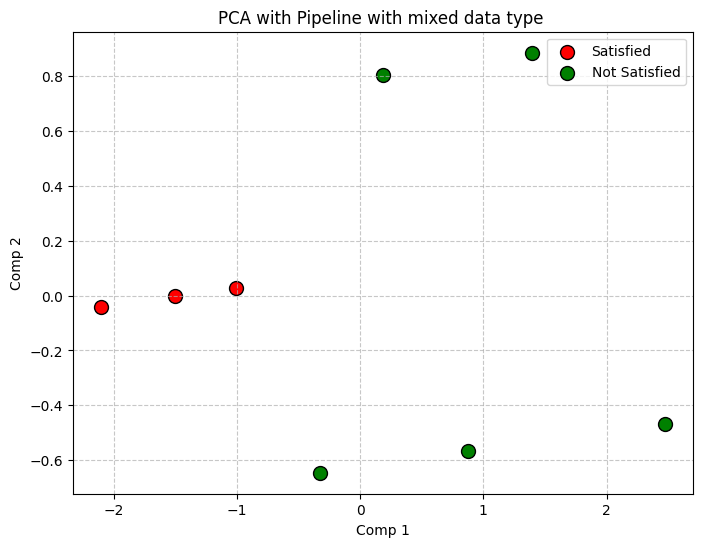

In [15]:
plt.figure(figsize=(8, 6))
classes = [0, 1]
colours = ["red", "green"]
labels = ["Satisfied", "Not Satisfied"]

for cla, col, lab in zip(classes, colours, labels):
    # Select only specific row per class
    plt.scatter(
        X_pca[y == cla, 0],
        X_pca[y == cla, 1],
        color=col,
        label=lab,
        s=100,  # dimension of the dot
        edgecolor="black",
    )

plt.title("PCA with Pipeline with mixed data type ")
plt.xlabel("Comp 1")
plt.ylabel("Comp 2")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.7)
plt.show()

# The Chart interpretation must be done considering that the position of the dot in the chart is given by 

$$\text{dot PCA} = \text{Value of the feature in the component standardised} \times \text{Loading}$$

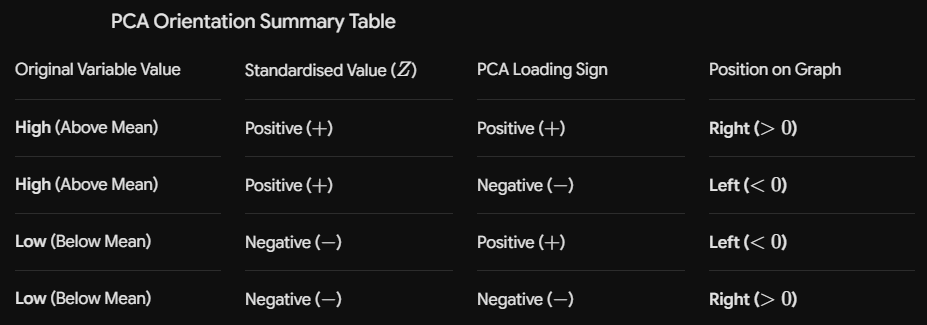

# Observation

### Interpretation of Comp 1 (X-axis – Horizontal)

* **What it contains:** `num__Income` (**0.69**) and `num__Age` (**0.69**).
* **Interpretation:** The X-axis represents the customer's **socio-economic and demographic profile**, with Income and Age increasing together towards the right.
* **What the graph shows:**

  * **On the left (values < -1):** These are the younger customers with lower incomes. The graph shows that **all Satisfied customers (red) are located in this area**.
  * **On the right (values > 0):** These are the older customers with higher incomes. The graph shows that **all Not Satisfied customers (green) are located in this area**.
* **Conclusion on Comp 1:** Customer dissatisfaction appears to be strongly associated with **higher age and higher income**.


### Interpretation of Comp 2 (Y-axis – Vertical)

* **What it contains:** `cat__City_Naples` (**+0.70**) and `cat__City_Rome` (**-0.70**).
* **Interpretation:** The Y-axis represents **geography (the customer's city)**. Moving upwards indicates Naples, while moving downwards indicates Rome, with Milan positioned in the middle.
* **What the graph shows:**

  * **Satisfied group (Red):** The red points are all concentrated around the centre ($Y \approx 0$). This suggests that **city does not have a strong influence** on satisfaction among younger/lower-income customers.
  * **Not Satisfied group (Green):** The green points are widely spread vertically (from $+0.9$ to $-0.6$). This suggests that among older/higher-income customers, dissatisfaction is distributed across different cities, including both Rome and Naples.


# What after the PCA

# ML Model

In [16]:
# 1 Train a ML Model

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X_pca, y, test_size=0.25, random_state=42
)

In [18]:
mod = LogisticRegression()
mod.fit(X_train, y_train)

LogisticRegression()

In [19]:
accuracy = mod.score(X_test, y_test)
print(f"Accuracy of model post-PCA: {accuracy * 100:.2f}%")

Accuracy of model post-PCA: 50.00%


# Clustering

In [20]:
# 2 Clustering
from sklearn.cluster import KMeans

In [21]:
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X_pca,y_train)

cluster_=kmeans.predict(X_test)

C:\Users\matti\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\matti\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.12_3.12.2800.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^

In [22]:
cluster_.shape

(2,)

In [23]:
print("Group assigned to each customer:", cluster_)

X_test = pd.DataFrame(X_test,columns = ['Comp1','Comp2'])


Group assigned to each customer: [2 0]


In [24]:
X_test['cluster'] = cluster_
X_test

,Comp1,Comp2,cluster
0,-0.328478,-0.645558,2
1,2.472358,-0.468166,0


# New Customer Prediction

In [25]:
new_customer = pd.DataFrame(
    {"Age":[18], "Income":[2000], "City": ["Milan"]}
)

In [26]:
new_client = pipeline_pca.transform(new_customer)

In [27]:
pred = mod.predict(new_client)

print(pred)

[0]
